In [ ]:
from typing import TypedDict

from langgraph.graph import END, START, StateGraph


In [42]:
# define state
class BMIState(TypedDict):
    weight_kg: float
    height_m: float
    bmi: float
    type: str

In [43]:
def claculate_bmi(state: BMIState) -> BMIState:
    w = state["weight_kg"]
    h = state["height_m"]

    bmi = w/(h**2)
    

    state["bmi"] = round(bmi, 2)

    return state

def classify_type(state: BMIState) -> BMIState:
    bmi = state["bmi"]

    if bmi<18.5:
        type = "underweight"
    elif bmi<25.0:
        type = "normal"
    elif bmi<30.0:
        type = "overweight"
    elif bmi<35.0:
        type = "obesity class 1"
    elif bmi<40.0:
        type = "obesity class 2"
    else:
        type = "obesity class 3"

    state["type"] = type

    return state

In [44]:
# define your graph
graph = StateGraph(BMIState)

# add nodes to your graph
graph.add_node("claculate_bmi", claculate_bmi)
graph.add_node("classify_type", classify_type)

# add edges to your graph
graph.add_edge(START, "claculate_bmi")
graph.add_edge("claculate_bmi", "classify_type")
graph.add_edge("classify_type", END)

# compile the graph
workflow = graph.compile()

In [50]:
# execute the graph
initial_state = {"weight_kg":62, "height_m": 1.65}

final_state = workflow.invoke(initial_state)

print(final_state)

{'weight_kg': 62, 'height_m': 1.65, 'bmi': 22.77, 'type': 'normal'}


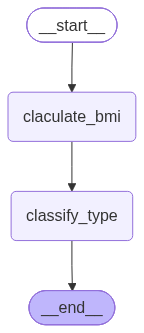

In [ ]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

# only works in jupyter nb